In [1]:
%pip install numpy opencv-python matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()
IMAGE_DIR = BASE_DIR / "images"
OUTPUT_DIR = BASE_DIR / "outputs"
IMAGE_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Working directory:", BASE_DIR)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

Working directory: C:\Users\venki\Computer_Vision_Practical
OpenCV: 4.12.0
NumPy: 2.2.6


Image shape: (1600, 1200)


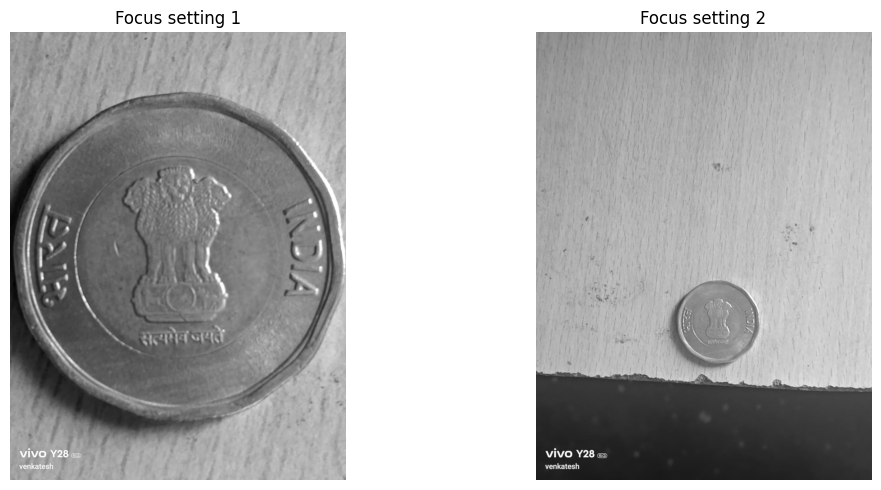

In [11]:
near_path = IMAGE_DIR / "focus_near.jpeg"
far_path = IMAGE_DIR / "focus_far.jpeg"

img_near = read_gray(near_path)
img_far = read_gray(far_path)

# Resize only if dimensions differ. This does NOT correct geometric misalignment.
if img_far.shape != img_near.shape:
    img_far = cv2.resize(img_far, (img_near.shape[1], img_near.shape[0]))

print("Image shape:", img_near.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_near, cmap="gray"); axes[0].set_title("Focus setting 1"); axes[0].axis("off")
axes[1].imshow(img_far, cmap="gray"); axes[1].set_title("Focus setting 2"); axes[1].axis("off")
plt.tight_layout()

## Cell 5 — DFD focus measure and relative focus map

The local squared-Laplacian response estimates sharpness. Positive values in the signed difference mean image 1 has the larger focus response; negative values mean image 2 does. The normalized colour map is a **relative focus comparison**, not metric depth.

Saved: C:\Users\venki\Computer_Vision_Practical\outputs\dfd_relative_focus.png


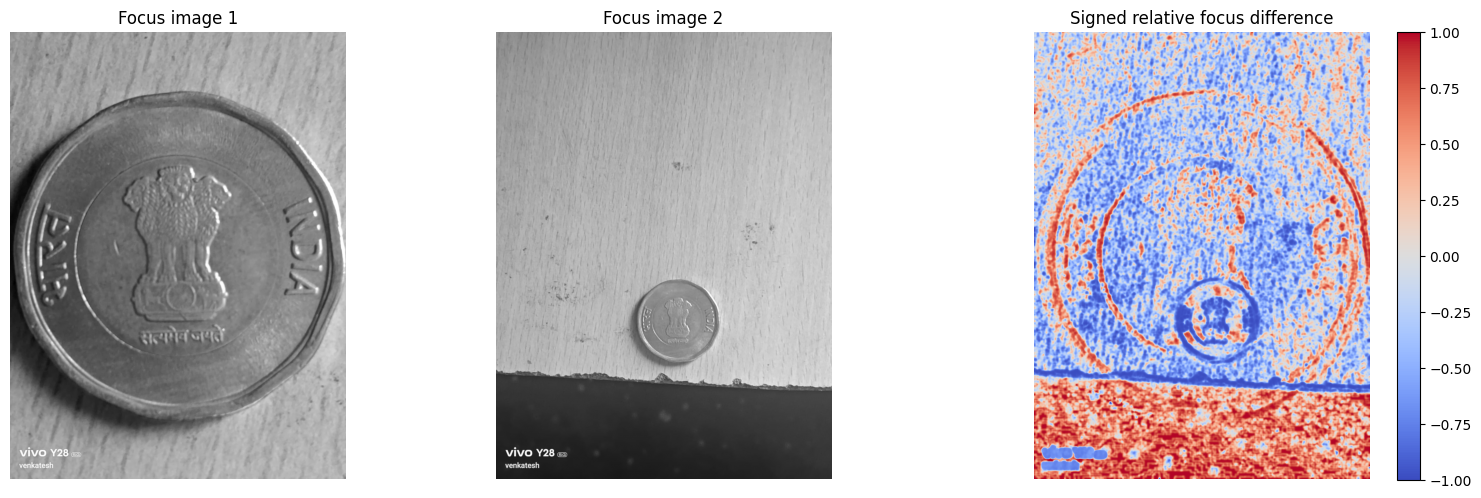

In [12]:
def local_focus_measure(gray, window=(15, 15)):
    smooth = cv2.GaussianBlur(gray, (3, 3), 0)
    lap = cv2.Laplacian(smooth, cv2.CV_64F)
    return cv2.GaussianBlur(lap ** 2, window, 0)

focus1 = local_focus_measure(img_near, (15, 15))
focus2 = local_focus_measure(img_far, (15, 15))

eps = 1e-8
focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)
dfd_vis = cv2.normalize(focus_diff, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(img_near, cmap="gray"); axes[0].set_title("Focus image 1"); axes[0].axis("off")
axes[1].imshow(img_far, cmap="gray"); axes[1].set_title("Focus image 2"); axes[1].axis("off")
im = axes[2].imshow(focus_diff, cmap="coolwarm", vmin=-1, vmax=1)
axes[2].set_title("Signed relative focus difference"); axes[2].axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()

save_image("dfd_relative_focus.png", dfd_vis)

## Cell 6 — Independent Task 1: Compare window sizes 7, 15 and 31

A small window preserves local detail but is more sensitive to noise. A large window averages over a wider area and looks smoother, but blurs boundaries between regions.

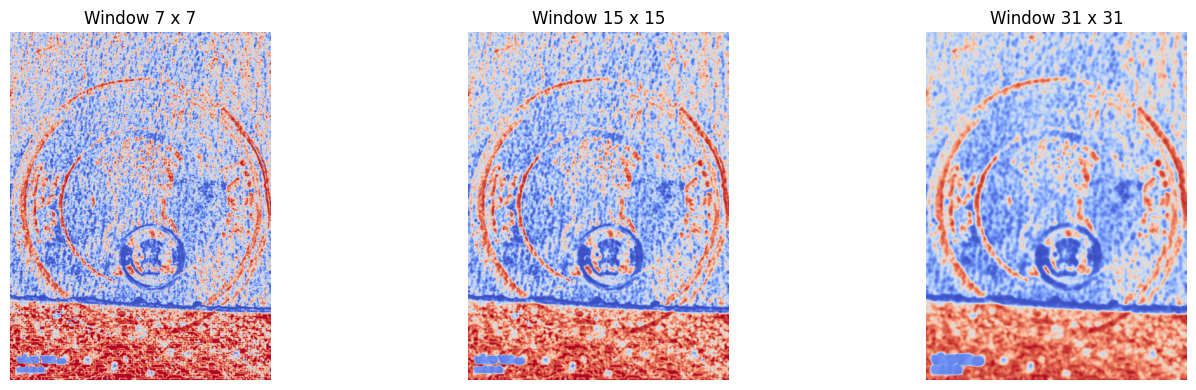

In [13]:
window_sizes = [7, 15, 31]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, size in zip(axes, window_sizes):
    f1 = local_focus_measure(img_near, (size, size))
    f2 = local_focus_measure(img_far, (size, size))
    diff = (f1 - f2) / (f1 + f2 + 1e-8)
    ax.imshow(diff, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(f"Window {size} x {size}")
    ax.axis("off")

plt.tight_layout()

## Cell 7 — Independent Task 2: Compare two focus measures

This compares the assignment's local mean of squared Laplacian with local variance of the Laplacian. They are related but not identical.

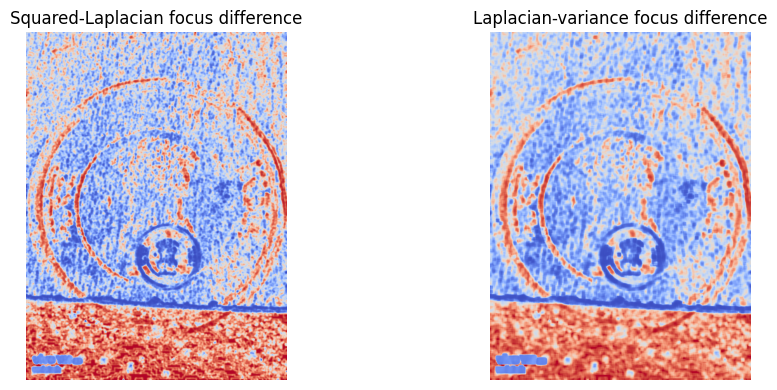

In [14]:
def laplacian_variance(gray, window=(15, 15)):
    smooth = cv2.GaussianBlur(gray, (3, 3), 0)
    lap = cv2.Laplacian(smooth, cv2.CV_64F)
    mean = cv2.blur(lap, window)
    mean_sq = cv2.blur(lap ** 2, window)
    return np.maximum(mean_sq - mean ** 2, 0)

var1 = laplacian_variance(img_near)
var2 = laplacian_variance(img_far)
variance_diff = (var1 - var2) / (var1 + var2 + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(focus_diff, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_title("Squared-Laplacian focus difference")
axes[1].imshow(variance_diff, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("Laplacian-variance focus difference")
for ax in axes: ax.axis("off")
plt.tight_layout()

## Cell 8 — Independent Task 3: Misalignment experiment

This deliberately shifts one image by a few pixels. Compare the result with the aligned map. The shifted map may show false changes around edges because corresponding pixels no longer represent the same scene point.

# Part B — Photometric Stereo

## Cell 9 — Load the four lighting images

All four images must have the same dimensions and show the same object/camera view. The light-direction rows below are examples from the assignment. **Replace them with the measured/recorded directions used for your photographs.** The result is not physically meaningful if the directions are guessed incorrectly.

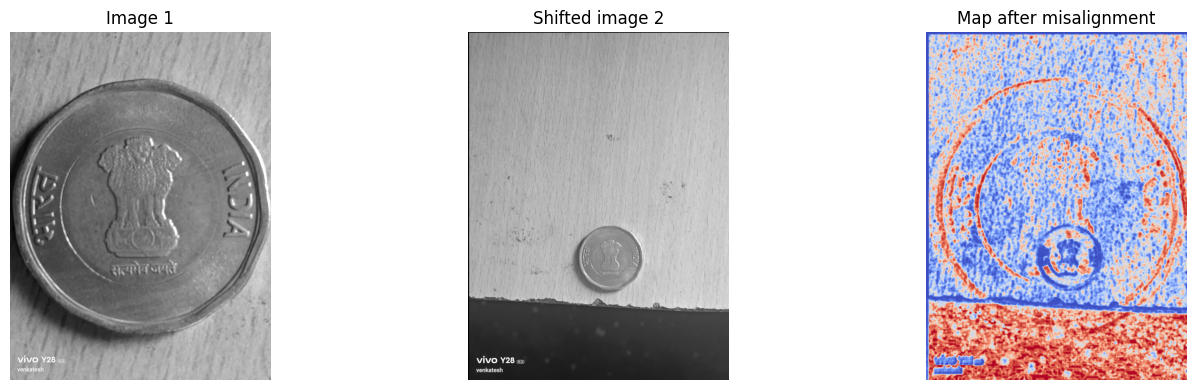

In [15]:
M = np.float32([[1, 0, 5], [0, 1, 3]])  # 5 px right, 3 px down
shifted = cv2.warpAffine(img_far, M, (img_far.shape[1], img_far.shape[0]))

f1 = local_focus_measure(img_near)
f2_shifted = local_focus_measure(shifted)
shift_diff = (f1 - f2_shifted) / (f1 + f2_shifted + 1e-8)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_near, cmap="gray"); axes[0].set_title("Image 1"); axes[0].axis("off")
axes[1].imshow(shifted, cmap="gray"); axes[1].set_title("Shifted image 2"); axes[1].axis("off")
axes[2].imshow(shift_diff, cmap="coolwarm", vmin=-1, vmax=1); axes[2].set_title("Map after misalignment"); axes[2].axis("off")
plt.tight_layout()

In [20]:
for i, img in enumerate(light_images, start=1):
    print(f"Light {i}: {img.shape}")


Light 1: (1600, 1200)
Light 2: (1600, 1200)
Light 3: (1200, 1600)
Light 4: (1200, 1600)


Photometric Stereo images loaded!
Stack shape: (4, 1600, 1200)


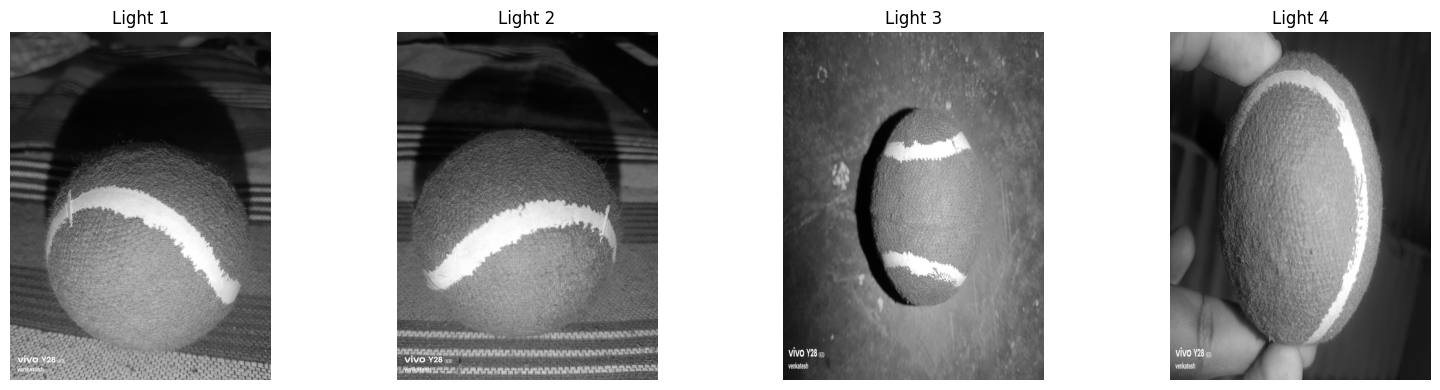

In [21]:
# 1. Load all four images
light_files = [
    IMAGE_DIR / "light1.jpeg",
    IMAGE_DIR / "light2.jpeg",
    IMAGE_DIR / "light3.jpeg",
    IMAGE_DIR / "light4.jpeg"
]

light_images = []

for file in light_files:
    img = read_gray(file)
    light_images.append(img)

# 2. Get dimensions from first image
target_height, target_width = light_images[0].shape

# 3. Resize remaining images
resized_images = []

for img in light_images:
    resized = cv2.resize(
        img,
        (target_width, target_height),
        interpolation=cv2.INTER_AREA
    )

    resized_images.append(
        resized.astype(np.float64) / 255.0
    )

# 4. Stack all images
I4 = np.stack(resized_images, axis=0)

print("Photometric Stereo images loaded!")
print("Stack shape:", I4.shape)

# 5. Display all four images
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, ax in enumerate(axes):
    ax.imshow(resized_images[i], cmap="gray")
    ax.set_title(f"Light {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import numpy as np

# Define four example lighting directions
L4 = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)

# Normalize lighting directions
L4 = L4 / np.linalg.norm(
    L4, axis=1, keepdims=True
)

print("Lighting matrix created!")
print(L4)

print("Matrix rank:", np.linalg.matrix_rank(L4))

Lighting matrix created!
[[ 0.   0.   1. ]
 [ 0.6  0.   0.8]
 [-0.6  0.   0.8]
 [ 0.   0.6  0.8]]
Matrix rank: 3


## Cell 10 — Photometric Stereo solver

For each pixel, solve `g = L⁺I`. The magnitude estimates albedo and the normalized vector estimates the surface normal. This basic Lambertian model is sensitive to shadows, shiny surfaces, changing exposure and inaccurate light directions.

Saved: C:\Users\venki\Computer_Vision_Practical\outputs\photometric_albedo.png
Saved: C:\Users\venki\Computer_Vision_Practical\outputs\photometric_normals.png


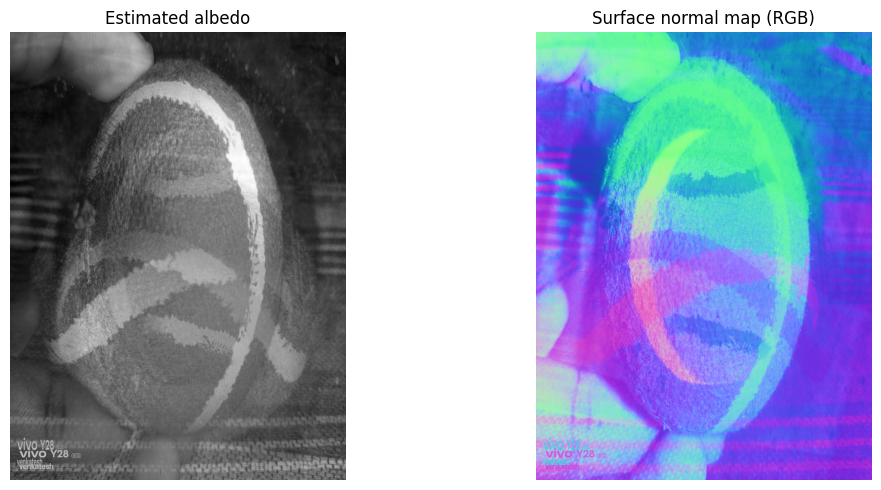

In [24]:
def estimate_photometric_stereo(image_stack, light_directions, mask=None):
    # image_stack shape: (m, h, w); light_directions shape: (m, 3)
    m, h, w = image_stack.shape
    L = np.asarray(light_directions, dtype=np.float64)
    if L.shape != (m, 3):
        raise ValueError("Need one 3D light direction for each input image.")
    if np.linalg.matrix_rank(L) < 3:
        raise ValueError("Lighting directions do not span 3D; use at least three non-coplanar directions.")

    L = L / (np.linalg.norm(L, axis=1, keepdims=True) + 1e-12)
    I_pixels = image_stack.reshape(m, -1)
    G = np.linalg.pinv(L) @ I_pixels

    albedo = np.linalg.norm(G, axis=0)
    normals = G / (albedo[None, :] + 1e-8)

    albedo = albedo.reshape(h, w)
    normals = normals.reshape(3, h, w).transpose(1, 2, 0)

    if mask is not None:
        albedo = albedo * mask
        normals = normals * mask[..., None]

    return albedo, normals

albedo4, normals4 = estimate_photometric_stereo(I4, L4)

nx, ny, nz = normals4[..., 0], normals4[..., 1], normals4[..., 2]
normal_rgb = np.clip((normals4 + 1) / 2, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(albedo4, cmap="gray"); axes[0].set_title("Estimated albedo"); axes[0].axis("off")
axes[1].imshow(normal_rgb); axes[1].set_title("Surface normal map (RGB)"); axes[1].axis("off")
plt.tight_layout()

albedo_vis = cv2.normalize(albedo4, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
normal_vis = (normal_rgb * 255).astype(np.uint8)
save_image("photometric_albedo.png", albedo_vis)
save_image("photometric_normals.png", cv2.cvtColor(normal_vis, cv2.COLOR_RGB2BGR))

## Cell 11 — Convert normals to gradients and integrate to relative depth

The assignment defines `p = -nx/nz` and `q = -ny/nz`. This notebook uses a simple row/column cumulative integration for demonstration. It is path-dependent and can accumulate error; it is not a high-accuracy surface integrator.

Saved: C:\Users\venki\Computer_Vision_Practical\outputs\photometric_depth.png


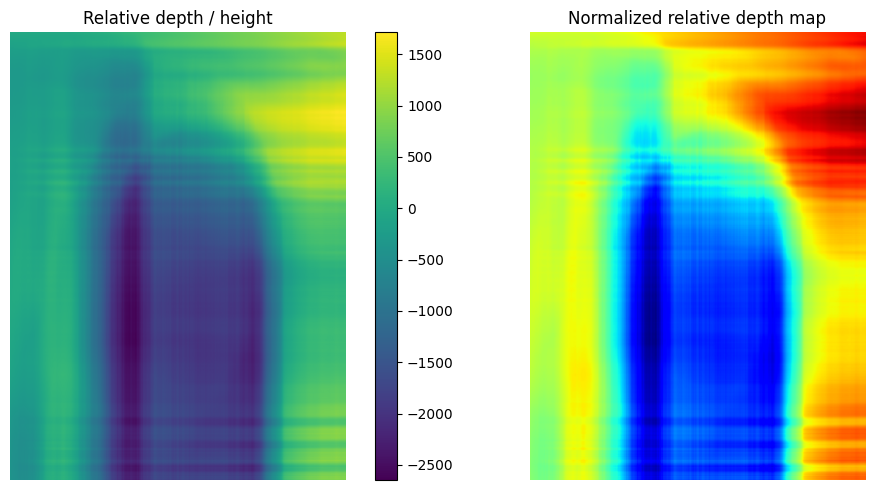

In [25]:
def integrate_gradients_simple(p, q):
    h, w = p.shape
    depth = np.zeros((h, w), dtype=np.float64)
    # Integrate horizontal gradient along the first row and each row.
    for y in range(h):
        depth[y, 1:] = np.cumsum(p[y, :-1])
    # Add vertical contribution.
    for x in range(w):
        depth[1:, x] += np.cumsum(q[:-1, x])
    return depth

valid = np.abs(nz) > 0.05
p = np.zeros_like(nx)
q = np.zeros_like(ny)
p[valid] = -nx[valid] / nz[valid]
q[valid] = -ny[valid] / nz[valid]

# Avoid extreme slopes near nz=0 from destabilizing the simple integration.
p = np.clip(p, -5, 5)
q = np.clip(q, -5, 5)

depth4 = integrate_gradients_simple(p, q)
depth4_vis = cv2.normalize(depth4, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(depth4, cmap="viridis")
axes[0].set_title("Relative depth / height")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)
axes[1].imshow(depth4_vis, cmap="jet")
axes[1].set_title("Normalized relative depth map")
axes[1].axis("off")
plt.tight_layout()

save_image("photometric_depth.png", depth4_vis)

## Cell 12 — Independent Task 5: Three-light versus four-light result

Three linearly independent light directions are the minimum for solving three normal components. A fourth or additional direction can improve robustness when the assumptions hold, but cannot fix incorrect lighting geometry or severe shadows.

Three-light matrix:
[[0.  0.  1. ]
 [0.6 0.  0.8]
 [0.  0.6 0.8]]
Matrix rank: 3


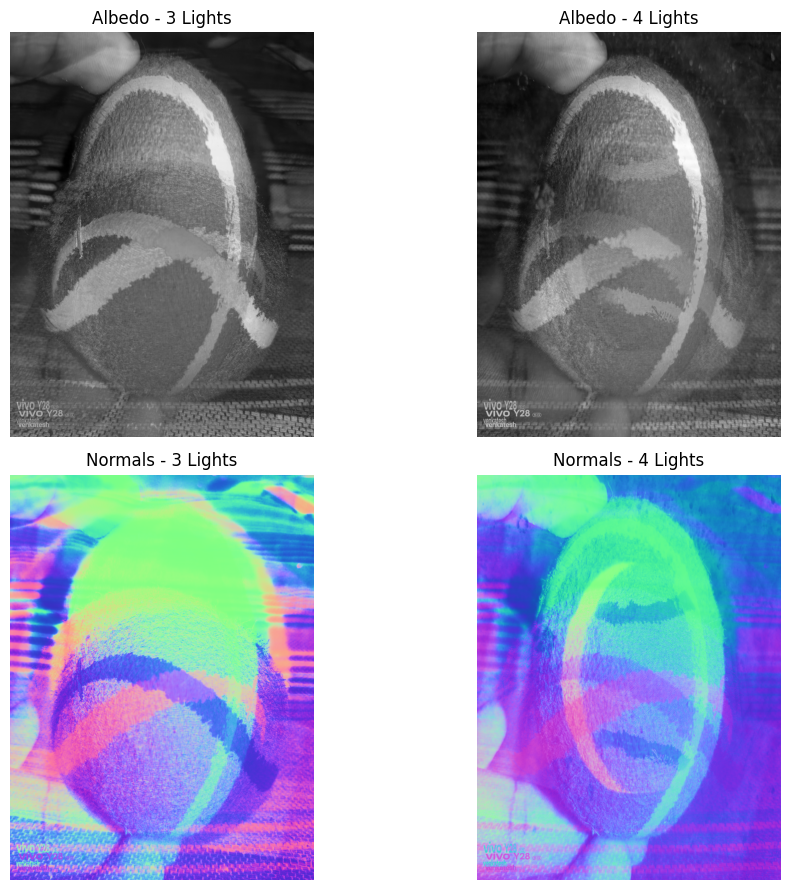

In [27]:
# Select three independent lighting directions
# Images 1, 2 and 4

I3 = I4[[0, 1, 3]]
L3 = L4[[0, 1, 3]]

print("Three-light matrix:")
print(L3)

print("Matrix rank:", np.linalg.matrix_rank(L3))

# Estimate albedo and surface normals
albedo3, normals3 = estimate_photometric_stereo(I3, L3)

normal3_rgb = np.clip((normals3 + 1) / 2, 0, 1)

# Compare three-light and four-light results
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

axes[0, 0].imshow(albedo3, cmap="gray")
axes[0, 0].set_title("Albedo - 3 Lights")

axes[0, 1].imshow(albedo4, cmap="gray")
axes[0, 1].set_title("Albedo - 4 Lights")

axes[1, 0].imshow(normal3_rgb)
axes[1, 0].set_title("Normals - 3 Lights")

axes[1, 1].imshow(normal_rgb)
axes[1, 1].set_title("Normals - 4 Lights")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Cell 13 — Independent Task 6: Create a foreground mask

This threshold-based example works only when the object is clearly separated from a contrasting background. Inspect the mask. If it selects the wrong region, adjust the threshold or create a mask manually; do not blindly trust it.

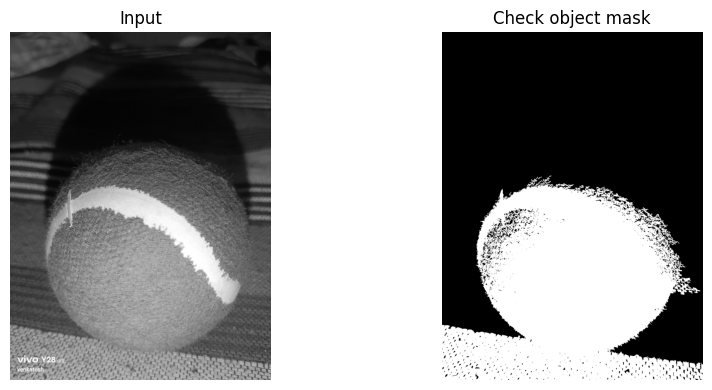

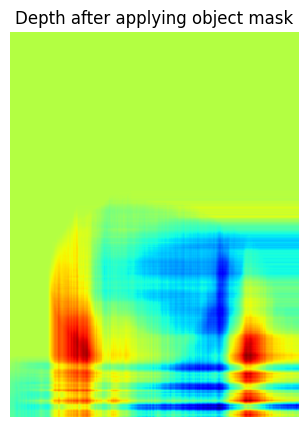

Saved: C:\Users\venki\Computer_Vision_Practical\outputs\photometric_depth_masked.png


In [28]:
# Starting point: Otsu threshold on the first lighting image.
first_u8 = (I4[0] * 255).astype(np.uint8)
_, object_mask = cv2.threshold(first_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Keep the larger connected foreground component (useful for a single isolated object).
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(object_mask, 8)
if num_labels > 1:
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    object_mask = np.where(labels == largest, 255, 0).astype(np.uint8)

mask = (object_mask > 0).astype(np.float64)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(first_u8, cmap="gray"); axes[0].set_title("Input"); axes[0].axis("off")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("Check object mask"); axes[1].axis("off")
plt.tight_layout()

# Re-estimate using mask
albedo_masked, normals_masked = estimate_photometric_stereo(I4, L4, mask=mask)
masked_nz = normals_masked[..., 2]
valid_m = (mask > 0) & (np.abs(masked_nz) > 0.05)

pm = np.zeros_like(masked_nz)
qm = np.zeros_like(masked_nz)
pm[valid_m] = -normals_masked[..., 0][valid_m] / masked_nz[valid_m]
qm[valid_m] = -normals_masked[..., 1][valid_m] / masked_nz[valid_m]
depth_masked = integrate_gradients_simple(np.clip(pm, -5, 5), np.clip(qm, -5, 5))
depth_masked_vis = cv2.normalize(depth_masked, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

show_image(depth_masked_vis, "Depth after applying object mask", cmap="jet")
save_image("photometric_depth_masked.png", depth_masked_vis)

## Cell 14 — Independent Task 4: Change lighting directions

This cell demonstrates why lighting geometry matters. The changed directions are only a simulation. Do not present them as the directions used to capture your real images.

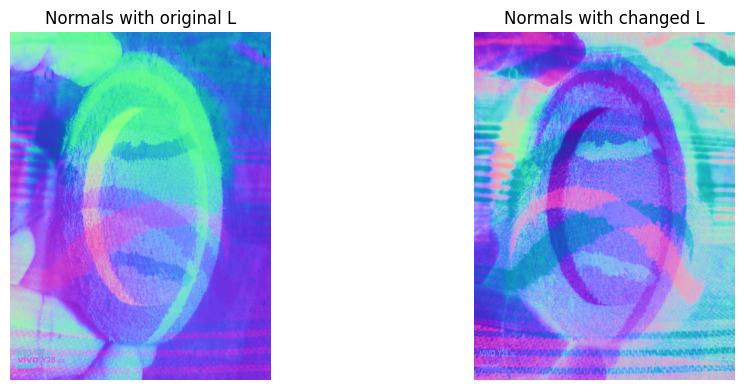

In [29]:
L_changed = np.array([
    [ 0.3,  0.0, 0.954],
    [-0.3,  0.0, 0.954],
    [ 0.0,  0.5, 0.866],
    [ 0.0, -0.5, 0.866]
], dtype=np.float64)
L_changed /= np.linalg.norm(L_changed, axis=1, keepdims=True)

albedo_changed, normals_changed = estimate_photometric_stereo(I4, L_changed)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(np.clip((normals4 + 1) / 2, 0, 1)); axes[0].set_title("Normals with original L"); axes[0].axis("off")
axes[1].imshow(np.clip((normals_changed + 1) / 2, 0, 1)); axes[1].set_title("Normals with changed L"); axes[1].axis("off")
plt.tight_layout()

## Cell 15 — Save a summary of all major outputs

In [30]:
# Save the main DFD and Photometric Stereo outputs.
save_image("dfd_relative_focus.png", dfd_vis)
save_image("photometric_albedo.png", albedo_vis)
save_image("photometric_depth.png", depth4_vis)

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(path.name)

Saved: C:\Users\venki\Computer_Vision_Practical\outputs\dfd_relative_focus.png
Saved: C:\Users\venki\Computer_Vision_Practical\outputs\photometric_albedo.png
Saved: C:\Users\venki\Computer_Vision_Practical\outputs\photometric_depth.png

Output files:
dfd_relative_focus.png
photometric_albedo.png
photometric_depth.png
photometric_depth_masked.png
photometric_normals.png
